In [1]:
from pathlib import Path

import numpy as np
import jax
import jax.numpy as jnp
import jax.scipy as jsp
import scipy
import matplotlib.pyplot as plt
import operator
from jax import config
from functools import partial
from matplotlib.lines import Line2D
config.update("jax_enable_x64", True)

import os

import polars as pl
import statistics

from cmfa.emu_example import ordered_ilr_func


In [2]:
RESULTS_DIR = Path("..") / "data" / "results" / "toy_example"

In [3]:
true_flux = np.load(RESULTS_DIR / "true_flux.npy")
true_flux

array([100., 110.,  50.,  20.,  20.,  80.])

In [4]:
true_composition = np.load(RESULTS_DIR / "true_composition.npy")
true_composition

array([6.34920635e-05, 8.00761905e-01, 1.98285714e-01, 8.88888889e-04])

In [5]:
intensity_measurements = np.load(RESULTS_DIR / "intensity_measurements.npy")
intensity_measurements.shape

(1000, 4)

In [6]:
estimated_fluxes_euclidean = np.load(RESULTS_DIR / "estimated_fluxes_euclidean.npy")
estimated_fluxes_euclidean.shape

(1000, 6)

In [7]:
estimated_fluxes_clr = np.load(RESULTS_DIR / "estimated_fluxes_clr.npy")
estimated_fluxes_clr.shape

(1000, 6)

In [8]:
estimated_fluxes_ilr = np.load(RESULTS_DIR / "estimated_fluxes_ilr.npy")
estimated_fluxes_ilr.shape

(1000, 6)

In [9]:
np.quantile(estimated_fluxes_euclidean, q=[0.05, 0.95], axis=0).T

array([[100.        , 100.        ],
       [ 89.45130635, 139.57592038],
       [ 34.63687768,  75.53444574],
       [ 17.43954322,  22.84662808],
       [ 17.43954322,  22.84662808],
       [ 77.15337192,  82.56045678]])

In [10]:
np.quantile(estimated_fluxes_clr, q=[0.05, 0.95], axis=0).T

array([[100.        , 100.        ],
       [ 90.69541158, 135.836714  ],
       [ 36.41166058,  71.75043656],
       [ 17.47111638,  22.86685267],
       [ 17.47111638,  22.86685267],
       [ 77.13314733,  82.52888362]])

In [11]:
estimated_fluxes_euclidean[214]

array([100.        , 210.962998  , 137.61829413,  13.32764806,
        13.32764806,  86.67235194])

In [12]:
true_flux

array([100., 110.,  50.,  20.,  20.,  80.])

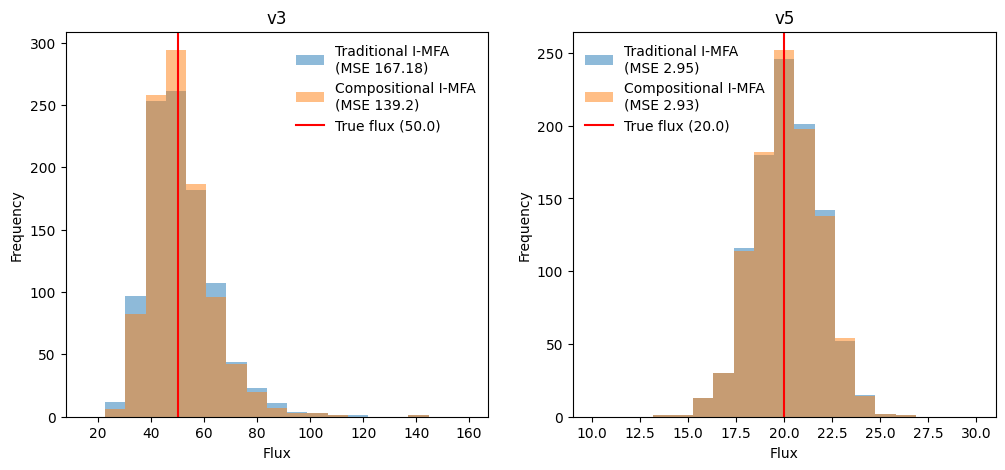

In [13]:
f, axes = plt.subplots(1, 2, figsize=[12, 5])

resid_euclidean = (estimated_fluxes_euclidean - true_flux)[:, [2, 4]] # index of free fluxes
resid_clr = (estimated_fluxes_clr - true_flux)[:, [2, 4]] # index of free fluxes
resid_ilr = (estimated_fluxes_ilr - true_flux)[:, [2, 4]] # index of free fluxes


mse_euclidean = (resid_euclidean ** 2).mean(axis=0)
mse_clr = (resid_clr ** 2).mean(axis=0)
mse_ilr = (resid_clr ** 2).mean(axis=0)


for (i, ax), xmin, xmax, flux_ix in zip(enumerate(axes), (15, 10), (160, 30), [2, 4]):
    bins = np.linspace(xmin, xmax, 20)
    h_euclidean = ax.hist(
        estimated_fluxes_euclidean[:, flux_ix], 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA\n(MSE {mse_euclidean[i].round(2)})" 
    )
    # h_clr = ax.hist(
    #     estimated_fluxes_clr[:, flux_ix], 
    #     bins=bins,
    #     alpha=0.5,
    #     label=f"Compositional I-MFA\n(MSE {mse_clr[i].round(2)})" 
    # )
    h_ilr = ax.hist(
        estimated_fluxes_ilr[:, flux_ix], 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA\n(MSE {mse_ilr[i].round(2)})" 
    )
    ax.axvline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]})")
    ax.set(title=f"v{flux_ix+1}", xlabel="Flux", ylabel="Frequency")
    ax.legend(frameon=False)

**Figure caption** Traditional vs Compositional I-MFA flux estimates on a toy model. We fit traditional and compositional I-MFA to 1000 simulated datasets based on the toy model in [Antoniewicz reference]. The datasets were simulated assuming noise on pre-closure measurements with constant coefficient of variation based on a model of mass spectrometer intensity measurements (lognormal scale parameter 0.1, corresponding to approximately 2% worst error after closure to compositions).

In [14]:
estimated_ids_euclidean = np.load(RESULTS_DIR / "estimated_ids_euclidean.npy")
estimated_ids_clr = np.load(RESULTS_DIR / "estimated_ids_clr.npy")
estimated_ids_ilr = np.load(RESULTS_DIR / "estimated_ids_ilr.npy")

comp_resid_euclidean = (estimated_ids_euclidean - true_composition)
comp_resid_clr = (estimated_ids_clr - true_composition)
comp_resid_ilr = (estimated_ids_ilr - true_composition)


((comp_resid_euclidean ** 2) - (comp_resid_ilr ** 2)).mean()

np.float64(9.457650162553889e-06)

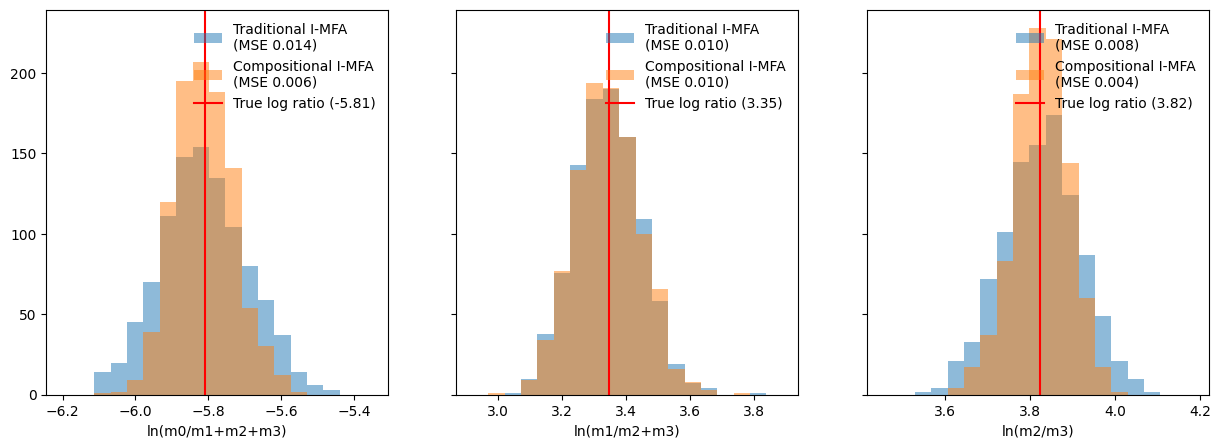

In [15]:
f, axes = plt.subplots(1, 3, sharey=True, figsize=[15, 5])

trad_ilrs = ordered_ilr_func(estimated_ids_euclidean)
comp_ilrs = ordered_ilr_func(estimated_ids_ilr)
clr_ilrs = ordered_ilr_func(estimated_ids_clr)

truth_ilrs = ordered_ilr_func(true_composition)

for (i, ax) in enumerate(axes):
    mse_trad = np.mean((trad_ilrs[:, i] - truth_ilrs[i]) ** 2)
    mse_comp = np.mean((comp_ilrs[:, i] - truth_ilrs[i]) ** 2)
    xmin = np.min(np.concat([trad_ilrs[:, i], comp_ilrs[:, i]])) - 0.1
    xmax = np.max(np.concat([trad_ilrs[:, i], comp_ilrs[:, i]])) + 0.1
    bins = np.linspace(xmin, xmax, 20)
    ax.hist(trad_ilrs[:, i], bins=bins, alpha=0.5, label=f"Traditional I-MFA\n(MSE {mse_trad:.3f})")
    ax.hist(comp_ilrs[:, i], bins=bins, alpha=0.5, label=f"Compositional I-MFA\n(MSE {mse_comp:.3f})")
    ax.axvline(truth_ilrs[i], color="red", label=f"True log ratio ({truth_ilrs[i]:.2f})")
    ax.legend(frameon=False)
    ratio_lhs = f"m{i}"
    ratio_rhs = "+".join([f"m{j}" for j in range(i+1, 4)])
    ax.set(xlabel=f"ln({ratio_lhs}/{ratio_rhs})")

**Figure caption** Traditional vs Compositional I-MFA isotopologue estimates on a toy model. Note that compositional I-MFA is far better than traditional I-MFA at estimating ratios that are sensitive to the low-abundance isotopologues m0 and m3.

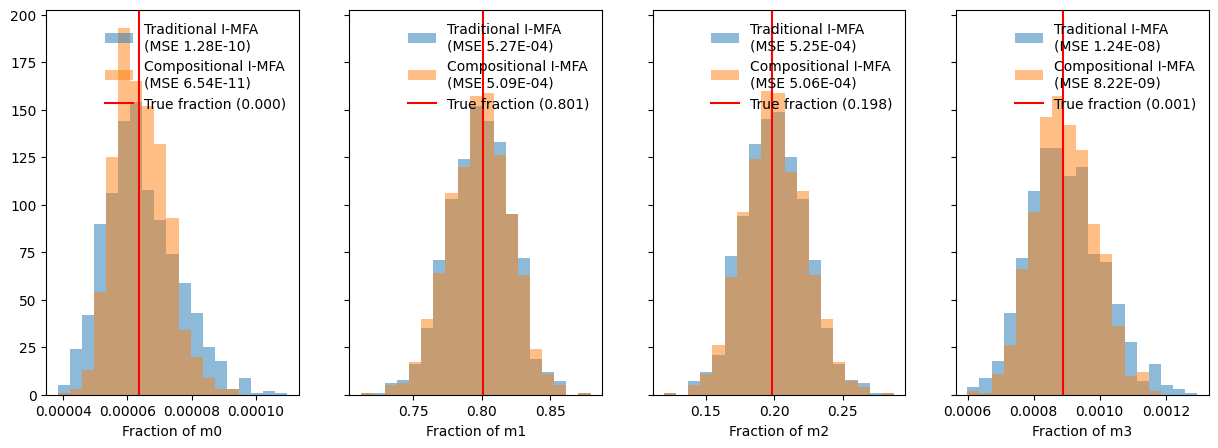

In [16]:
f, axes = plt.subplots(1, 4, sharey=True, figsize=[15, 5])

trad = estimated_ids_euclidean
comp = estimated_ids_ilr
truth = true_composition

for (i, ax) in enumerate(axes):
    mse_trad = np.mean((trad[:, i] - truth[i]) ** 2)
    mse_comp = np.mean((comp[:, i] - truth[i]) ** 2)
    xmin = np.min(np.concat([trad[:, i], comp[:, i]]))
    xmax = np.max(np.concat([trad[:, i], comp[:, i]]))
    bins = np.linspace(xmin, xmax, 20)
    ax.hist(trad[:, i], bins=bins, alpha=0.5, label=f"Traditional I-MFA\n(MSE {mse_trad:.2E})")
    ax.hist(comp[:, i], bins=bins, alpha=0.5, label=f"Compositional I-MFA\n(MSE {mse_comp:.2E})")
    ax.axvline(truth[i], color="red", label=f"True fraction ({truth[i]:.3f})")
    ax.legend(frameon=False)
    ax.set(xlabel=f"Fraction of m{i}")

[Text(0.5, 0, 'ln(m0/m1+m2+m3)'),
 Text(0.5, 0.5, 'ln(m2/m2+m3)'),
 Text(0.5, 0, 'ln(m2/m3)')]

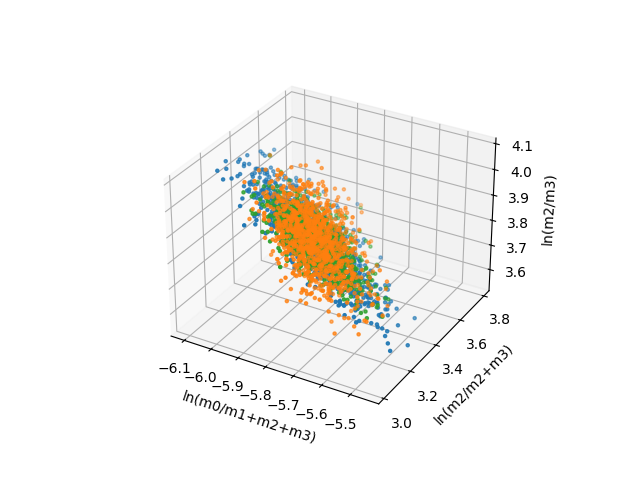

In [17]:
%matplotlib ipympl
fig, ax = plt.subplots(subplot_kw={'projection': '3d'})
ax.scatter(trad_ilrs[:, 0], trad_ilrs[:, 1], trad_ilrs[:, 2], s=5)
ax.scatter(comp_ilrs[:, 0], trad_ilrs[:, 1], trad_ilrs[:, 2], s=5)
ax.scatter(clr_ilrs[:, 0], clr_ilrs[:, 1], clr_ilrs[:, 2], s=5)

ax.set(xlabel="ln(m0/m1+m2+m3)", ylabel="ln(m2/m2+m3)", zlabel="ln(m2/m3)")